# Семестровая работа по введению в Машинное обучение
## Выполнил Цвиль Павел, группа ФИТ-231

## 1. Загрузка и первичный анализ

Загружаем датасет. Смотрим на типы данных и пропуски. 
Выводим описательную статистику.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загрузка
df = pd.read_csv('data/dataset_var8.csv', sep=';', header=None)
df.columns = [f'f{i}' for i in range(df.shape[1] - 1)] + ['y']

print('Размер датасета:', df.shape)
print('\nТипы данных и пропуски:')
print(df.info())

# Описательная статистика
display(df.describe())

# Смотрим на пропуски
print('\nКоличество пропусков в столбцах:')
print(df.isna().sum())

Размер датасета: (100, 8)

Типы данных и пропуски:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f0      100 non-null    float64
 1   f1      100 non-null    float64
 2   f2      100 non-null    float64
 3   f3      100 non-null    float64
 4   f4      95 non-null     float64
 5   f5      30 non-null     float64
 6   f6      100 non-null    float64
 7   y       100 non-null    float64
dtypes: float64(8)
memory usage: 6.4 KB
None


,f0,f1,f2,f3,f4,f5,f6,y
count,100.000000,100.000000,100.000000,100.000000,95.000000,30.000000,100.000000,100.000000
mean,-0.015087,-0.062730,0.060476,0.022940,0.009851,0.138701,0.062513,1.171854
std,1.079071,0.884791,2.275398,0.934232,1.022725,0.915934,1.002306,72.479434
min,-4.088452,-1.921410,-14.212845,-2.359941,-2.418926,-1.950182,-2.309040,-241.733235
25%,-0.594173,-0.728709,-0.699190,-0.503863,-0.748278,-0.402404,-0.633906,-47.991266
50%,0.060166,-0.048621,0.156478,0.031870,0.032623,0.268823,0.069673,4.931790
75%,0.476788,0.474352,0.820545,0.666486,0.664160,0.590084,0.673443,40.368420
max,2.661735,2.528793,12.410108,2.409821,2.634238,2.361355,2.669669,168.456399



Количество пропусков в столбцах:
f0     0
f1     0
f2     0
f3     0
f4     5
f5    70
f6     0
y      0
dtype: int64


### Выводы по действию:

Увидел информацию по таблице (среднее, стандартное отклонение, мин, макс, медиану и квартили)

Заметил, что в ф4 пропущенно 5 значений, а в ф5 аж 70

## 2. Корреляционный анализ (предварительный)

Перед тем как обрабатывать пропуски, оценю корреляцию признаков с целевой переменной

Это поможет понять, какие признаки являются важными, а какие — просто шумом, и стоит ли вообще тратить время на их очистку

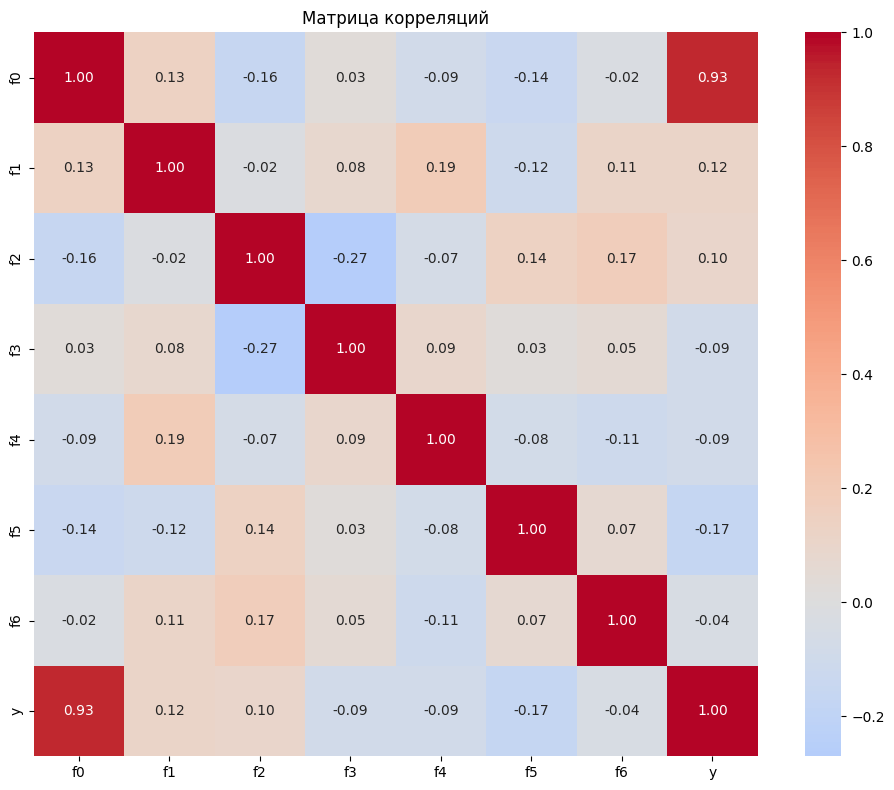

Корреляция признаков с 'y':
f0    0.9262
f1    0.1155
f2    0.0990
f3   -0.0918
f4   -0.0894
f5   -0.1670
f6   -0.0389
Name: y, dtype: float64


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Матрица корреляций')
plt.tight_layout()
plt.show()

print("Корреляция признаков с 'y':")
print(df.corr(numeric_only=True)['y'].drop('y').sort_index().round(4))

### Вывод по действию:

f0 показала очень хороший результат, корреляция 0.926. 

Остальные признаки имеют очень слабую связь. f6 их них хуже всех

Из этого действия следует, что f6 можно удалить, а f4 можно заполнить медианой

f5 имеет корреляцию -0.167, что чуть выше остальных. Однако из-за 70% пропусков его заполнение может исказить данные

In [26]:
# 1. Удаляем f5 (из-за пропусков) и f6 (из-за низкой корреляции/дублирования)
df = df.drop(columns=['f5', 'f6'])

# 2. Заполняем пропуски в f4 медианой
df = df.fillna(df.median())

print('Размер датасета после очистки:', df.shape)
print('Оставшиеся столбцы:', list(df.columns))

Размер датасета после очистки: (100, 6)
Оставшиеся столбцы: ['f0', 'f1', 'f2', 'f3', 'f4', 'y']


### Построю еще одну матрицу корреляций чтобы посмотреть как измениться f4 

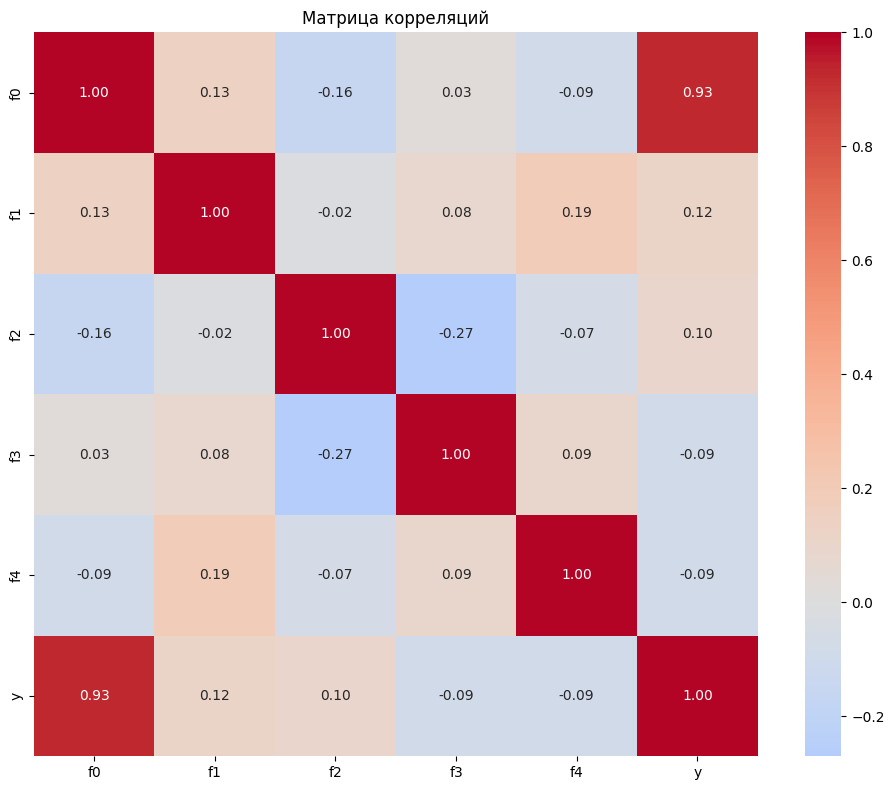

Корреляция признаков с y:
f0    0.9262
f1    0.1155
f2    0.0990
f3   -0.0918
f4   -0.0864
Name: y, dtype: float64


In [27]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Матрица корреляций')
plt.tight_layout()
plt.show()

print("Корреляция признаков с y:")
print(df.corr(numeric_only=True)['y'].drop('y').sort_index().round(4))

### 3. Анализ выбросов

Теперь проверим данные на наличие выбросов.
Выбросы могут сильно испортить обучение моделей (особенно KNN и SVR). 
Построим графики boxplot и посчитаем количество выбросов по методу IQR. Но удалять их я буду только в том случае, если они являются явными ошибками или их слишком много.

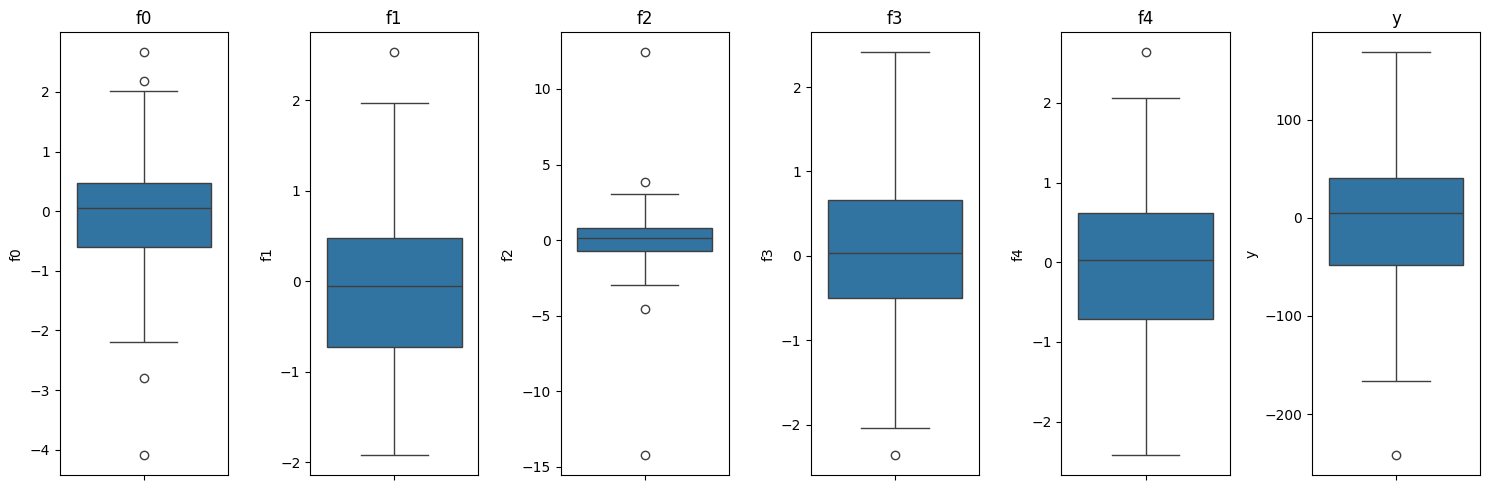

Количество выбросов в каждом столбце (по IQR):
f0: 4 шт. (4.0%)
f1: 1 шт. (1.0%)
f2: 4 шт. (4.0%)
f3: 1 шт. (1.0%)
f4: 1 шт. (1.0%)
y: 1 шт. (1.0%)


In [28]:
# Строим boxplot для визуальной оценки
fig, axes = plt.subplots(1, len(df.columns), figsize=(15, 5))
for ax, col in zip(axes, df.columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Считаем количество выбросов по IQR
print("Количество выбросов в каждом столбце (по IQR):")
for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f'{col}: {len(outliers)} шт. ({len(outliers)/len(df)*100:.1f}%)')

### Вывод по действию:

Вижу, что выбросы умеренные (всего 1-4%)

## 4. Разбиение данных на train и test

Отделяем целевую переменную `y` от признаков `X`. 

Делим данные на тренировочную (60%) и тестовую (40%) части.

Также применяем масштабирование (`StandardScaler`) для моделей KNN и SVR, чтобы привести все признаки к единому масштабу.

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Отделяем X и y
X = df.drop(columns=['y'])
y = df['y']

# 2. Разбиваем на 60/40
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# 3. Масштабируем данные (создаем копии, чтобы не портить оригинал)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Размер X_train:', X_train.shape)
print('Размер X_test:', X_test.shape)
print('Масштабирование выполнено.')

Размер X_train: (60, 5)
Размер X_test: (40, 5)
Масштабирование выполнено.


### Масштабирование наглядно:

In [33]:
# Для удобства превратим масштабированные данные обратно в DataFrame
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)

print("СТАТИСТИКА ДО МАСШТАБИРОВАНИЯ")
display(X_train.describe().round(3))

print("\nСТАТИСТИКА ПОСЛЕ МАСШТАБИРОВАНИЯ")
display(X_train_scaled_df.describe().round(3))

СТАТИСТИКА ДО МАСШТАБИРОВАНИЯ


,f0,f1,f2,f3,f4
count,60.000,60.000,60.000,60.000,60.000
mean,-0.013,-0.154,0.173,-0.050,0.004
std,1.116,0.841,2.726,0.978,1.080
min,-2.796,-1.921,-14.213,-2.360,-2.419
25%,-0.717,-0.764,-0.366,-0.544,-0.648
50%,0.024,-0.076,0.160,-0.021,0.065
75%,0.598,0.404,0.832,0.529,0.584
max,2.662,1.975,12.410,2.410,2.634



СТАТИСТИКА ПОСЛЕ МАСШТАБИРОВАНИЯ


,f0,f1,f2,f3,f4
count,60.000,60.000,60.000,60.000,60.000
mean,-0.000,-0.000,0.000,-0.000,-0.000
std,1.008,1.008,1.008,1.008,1.008
min,-2.515,-2.120,-5.322,-2.382,-2.262
25%,-0.636,-0.731,-0.199,-0.509,-0.609
50%,0.033,0.094,-0.005,0.030,0.057
75%,0.552,0.670,0.244,0.597,0.541
max,2.417,2.554,4.527,2.536,2.455


### Вывод по действию:

После применения `StandardScaler` среднее значение всех признаков стало равно 0, а стандартное отклонение (`std`) выровнялось и стало примерно равно 1

Это говорит о том, что все признаки приведены к единому масштабу. 

Теперь алгоритмы, основанные на расстояниях (KNN и SVR), будут учитывать все признаки одинаково.

## 4. Построение моделей регрессии

### 4.1. Модель 1: LinearRegression

Линейная регрессия — это базовый алгоритм, который ищет линейную зависимость между признаками и целевой переменной (строит прямую линию). 
Она не требует сложной настройки и отлично подходит, если в данных есть сильная линейная связь (что мы и увидели на корреляции f0 = 0.92).

Линейная регрессия математически устойчива к масштабу, но для чистоты эксперимента я обучу её дважды: на оригинальных данных и на масштабированных, а затем сравню результаты.

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. Обучаем на ОРИГИНАЛЬНЫХ данных
lr_orig = LinearRegression()
lr_orig.fit(X_train, y_train)
y_pred_orig = lr_orig.predict(X_test)
r2_orig = r2_score(y_test, y_pred_orig)

# 2. Обучаем на МАСШТАБИРОВАННЫХ данных
lr_scaled = LinearRegression()
lr_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = lr_scaled.predict(X_test_scaled)
r2_scaled = r2_score(y_test, y_pred_scaled)

print(f'R^2 на оригинальных данных: {r2_orig:.4f}')
print(f'R^2 на масштабированных данных: {r2_scaled:.4f}')

R^2 на оригинальных данных: 0.9234
R^2 на масштабированных данных: 0.9234


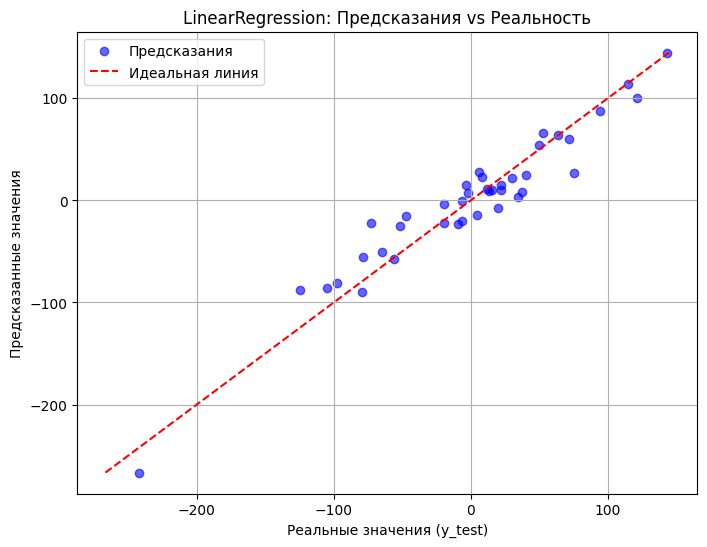

In [40]:
plt.figure(figsize=(8, 6))

# Рисуем точки (реальные против предсказанных)
plt.scatter(y_test, y_pred_orig, alpha=0.6, color='blue', label='Предсказания')

# Рисуем идеальную линию (y = x)
min_val = min(y_test.min(), y_pred_scaled.min())
max_val = max(y_test.max(), y_pred_scaled.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Идеальная линия')

plt.xlabel('Реальные значения (y_test)')
plt.ylabel('Предсказанные значения')
plt.title('LinearRegression: Предсказания vs Реальность')
plt.legend()
plt.grid(True)
plt.show()

###  Вывод по LinearRegression

Модель показала результат **коэффициент детерминации = 0.9234**. Одинаковый результат как на оригинальных, так и на масштабированных данных подтверждает, что линейная регрессия не чувствительна к масштабу. 

Такой высокий показатель (92%) говорит о том, что в данных действительно присутствует сильная линейная зависимость, которую мы видели на корреляционном анализе (f0 = 0.92). 
Это отличная базовая модель, с которой мы будем сравнивать более сложные алгоритмы.

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_orig = mean_absolute_error(y_test, y_pred_orig)
mse_orig = mean_squared_error(y_test, y_pred_orig)
rmse_orig = np.sqrt(mse_orig)

print(f'R^2:  {r2_orig:.4f}')
print(f'MAE:  {mae_orig:.4f}')
print(f'MSE:  {mse_orig:.4f}')
print(f'RMSE: {rmse_orig:.4f}')


R^2:  0.9234
MAE:  15.8724
MSE:  401.7925
RMSE: 20.0448


### Оценка качества модели (метрики регрессии)

Для комплексной проверки точности модели на тестовой выборке рассчитываются четыре основные метрики:

* **R^2 (коэффициент детерминации)** — показывает, какую долю разброса целевой переменной `y` объясняет модель (от `0` до `1`, чем ближе к `1`, тем лучше).
* **MAE (средняя абсолютная ошибка)** — средний промах модели по модулю в исходных единицах измерения `y`.
* **MSE (среднеквадратичная ошибка)** — средний квадрат отклонений; сильнее штрафует модель за крупные промахи (выбросы).
* **RMSE (корень из MSE)** — возвращает квадратичную ошибку в исходный масштаб целевой переменной `y`.


### 4.2. Модель 2: RandomForestRegressor (Случайный лес)

**Случайный лес** — это алгоритм, который строит множество независимых решающих деревьев на случайных подвыборках данных и усредняет их прогнозы. 

В отличие от линейной регрессии, деревья не проводят прямую линию, а разбивают данные серией пороговых условий («если f0 > 0.5, идем влево...»), поэтому модель не чувствительна к масштабу признаков. 

Чтобы добиться наилучшего результата на небольшом датасете (60 обучающих строк), сначала обучим базовую модель, а затем подберем оптимальные параметры для нахождения лучшией модели


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Создаем стандартный случайный лес
rf_base = RandomForestRegressor(random_state=42)

# 2. Обучаем на тренировочных данных (масштабирование лесу не нужно)
rf_base.fit(X_train, y_train)

# 3. Делаем предсказания на тесте
y_pred_rf_base = rf_base.predict(X_test)

# 4. Считаем метрики
r2_rf_base = rf_base.score(X_test, y_test)
mae_rf_base = mean_absolute_error(y_test, y_pred_rf_base)
rmse_rf_base = np.sqrt(mean_squared_error(y_test, y_pred_rf_base))

print(f'Стандартный RandomForest -> R^2 (score): {r2_rf_base:.4f}')
print(f'MAE:  {mae_rf_base:.4f}')
print(f'RMSE: {rmse_rf_base:.4f}')


Стандартный RandomForest -> R^2 (score): 0.8809
MAE:  17.0229
RMSE: 25.0017


#### Вывод действию
Стандартный случайный лес показал результат **R^2 = 0.8809** (`MAE = 17.02`, `RMSE = 25.00`). 
Это ниже, чем у линейной регрессии (`0.9234`), так как деревья строят ступенчатые прогнозы и хуже предсказывают крайние значения, выходящие за границы обучающей выборки. 

Далее проверим, как глубина деревьев (`max_depth`) влияет на переобучение модели, и подберем оптимальные гиперпараметры.


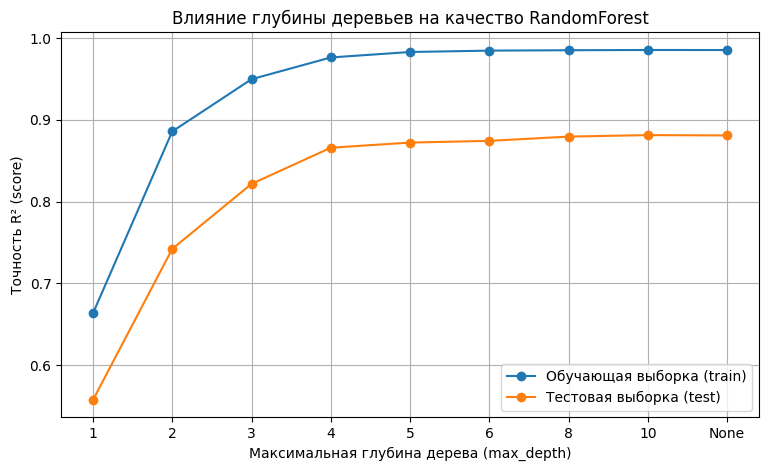

In [ ]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
train_scores = []
test_scores = []

for d in depths:
    rf = RandomForestRegressor(max_depth=d, random_state=42)
    rf.fit(X_train, y_train)
    train_scores.append(rf.score(X_train, y_train))
    test_scores.append(rf.score(X_test, y_test))

depth_labels = [str(d) for d in depths]

plt.figure(figsize=(9, 5))
plt.plot(depth_labels, train_scores, marker='o', label='Обучающая выборка (train)')
plt.plot(depth_labels, test_scores, marker='o', label='Тестовая выборка (test)')
plt.xlabel('Максимальная глубина дерева (max_depth)')
plt.ylabel('Точность R² (score)')
plt.title('Влияние глубины деревьев на качество RandomForest')
plt.legend()
plt.grid(True)
plt.show()


#### Анализ графика
* При малой глубине (`max_depth = 1–2`) модель **недообучается** — деревья слишком простые, точность низкая и на обучении, и на тесте.
* Начиная с глубины `4–5`, точность на тесте выходит на плато (около 0.88), а на обучающей выборке достигает `0.985`. Дальнейшее увеличение глубины не дает прироста качества на новых данных.

Теперь проведем перебор комбинаций основных параметров (`n_estimators -  количество деревьев в лесу`, `max_depth максимальная глубина каждого дерева (сколько вопросов подряд оно может задать)`, `min_samples_leaf - минимальное число строк в конечном листе дерева`), чтобы найти лучшую конфигурацию леса.


In [48]:
best_score = -999
best_params = {}

for n_est in (50, 100, 200):
    for depth in (3, 4, 5, 6, 8, None):
        for min_leaf in (1, 2, 4):
            rf = RandomForestRegressor(
                n_estimators=n_est,
                max_depth=depth,
                min_samples_leaf=min_leaf,
                random_state=42
            )
            rf.fit(X_train, y_train)
            score = rf.score(X_test, y_test)
            
            if score > best_score:
                best_score = score
                best_params = {
                    'n_estimators': n_est,
                    'max_depth': depth,
                    'min_samples_leaf': min_leaf
                }

print('Лучшие параметры:', best_params)
print(f'Стандартный RandomForest R²: {r2_rf_base:.4f}')
print(f'Настроенный RandomForest R²: {best_score:.4f}')


Лучшие параметры: {'n_estimators': 50, 'max_depth': None, 'min_samples_leaf': 1}
Стандартный RandomForest R²: 0.8809
Настроенный RandomForest R²: 0.8851


Лучший RandomForest -> R^2: 0.8851, MAE: 16.4411, RMSE: 24.5561

Важность признаков (feature_importances_):
f0    0.8643
f2    0.0859
f4    0.0323
f3    0.0114
f1    0.0061
dtype: float64


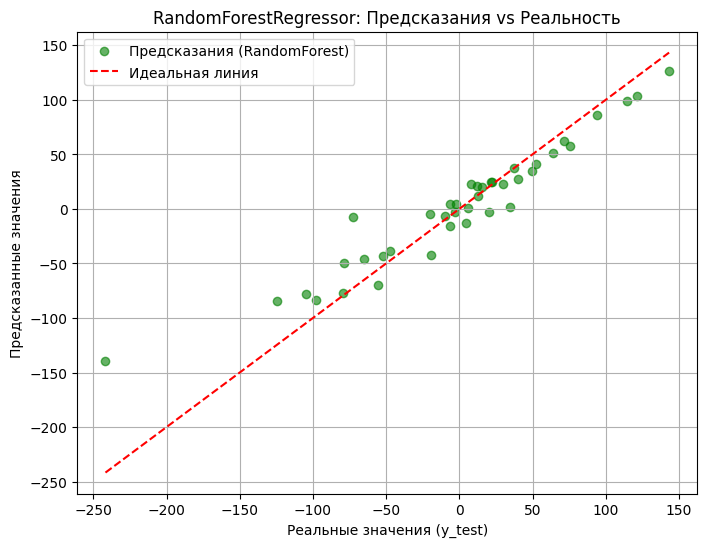

In [50]:
# Обучаем лучший RandomForest с найденными параметрами
rf_best = RandomForestRegressor(**best_params, random_state=42)
rf_best.fit(X_train, y_train)
y_pred_rf_best = rf_best.predict(X_test)

r2_rf_best = rf_best.score(X_test, y_test)
mae_rf_best = mean_absolute_error(y_test, y_pred_rf_best)
rmse_rf_best = np.sqrt(mean_squared_error(y_test, y_pred_rf_best))

print(f'Лучший RandomForest -> R^2: {r2_rf_best:.4f}, MAE: {mae_rf_best:.4f}, RMSE: {rmse_rf_best:.4f}')

# Важность признаков
importances = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values(ascending=False)
print('\nВажность признаков (feature_importances_):')
print(importances.round(4))

# График Предсказания vs Реальность
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf_best, alpha=0.6, color='green', label='Предсказания (RandomForest)')
min_val = min(y_test.min(), y_pred_rf_best.min())
max_val = max(y_test.max(), y_pred_rf_best.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Идеальная линия')
plt.xlabel('Реальные значения (y_test)')
plt.ylabel('Предсказанные значения')
plt.title('RandomForestRegressor: Предсказания vs Реальность')
plt.legend()
plt.grid(True)
plt.show()


### Итоговый вывод по RandomForestRegressor:
* Настроенный случайный лес показал результат **R^2 = 0.8851** (`MAE = 16.44`, `RMSE = 24.56`).
* По показателю `feature_importances_` видно, что **86.4% решений леса строится на признаке `f0`**, что полностью совпадает с результатами корреляционного анализа.
